# Large context with SAP-RPT-1.6-large and `context_mode="deep"`

RPT learns from the example rows you send with each request (the **context**). As a rule, more relevant examples give better answers. How many examples a request can carry depends on the model:

| Model | Max context rows | Recommended |
|---|---|---|
| `sap-rpt-1.6` | 2,048 | 500-2,000 |
| `sap-rpt-1.6-large` | 65,536 | 4,000-36,000 |

`sap-rpt-1.6-large` also has a setting `prediction_config.context_mode`:

* `"default"`: the best balance of accuracy and speed;
* `"deep"`: spends more time per request to reach higher accuracy when there is a lot of context. SAP recommends it **only with `sap-rpt-1.6-large` and more than 8,000 context rows**, and recommends trying, in this order, `sap-rpt-1.6`, then `sap-rpt-1.6-large` with `default`, then `deep`.

This notebook follows that order on a real dataset with about 15,000 example rows and measures what each step brings:

1. `sap-rpt-1.6` with a random sample of 2,048 rows (its maximum);
2. `sap-rpt-1.6-large` with all rows, `default` mode;
3. `sap-rpt-1.6-large` with all rows, `deep` mode.

## 1. Setup

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import find_dotenv, load_dotenv
from tqdm.auto import tqdm

from rpt_client_api import RPTClientAPI

_ = load_dotenv(find_dotenv(usecwd=True))
pd.set_option("display.width", 160)

/Users/I760054/Documents/programs/Best Practices/sap-btp-ai-best-practices/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. The data

`data/OVERNIGHTSTAYS.csv` comes from the Swiss Federal Statistical Office hotel sector statistics (dataset px-x-1003020000_103). Each row is the number of **overnight stays** (one guest spending one night in a hotel) for one combination of:

* **month** (January 2022 to May 2024),
* **tourism region** (13 regions such as Graubünden, Zurich Region, Ticino),
* **country of residence** of the guests (77 countries or country groups).

The task: **estimate the overnight stays of a month for every region x country combination**, using earlier months as examples. That is 1,001 values per month.

`MONTH` is stored as `DD/MM/YYYY`; RPT expects dates as `YYYY-MM-DD`, so it is converted while reading.

In [2]:
stays = pd.read_csv("data/OVERNIGHTSTAYS.csv", encoding="utf-8-sig")
stays["MONTH"] = pd.to_datetime(stays["MONTH"], format="%d/%m/%Y")
print(stays.shape, "| months:", stays["MONTH"].nunique(),
      "| regions:", stays["REGION"].nunique(), "| countries:", stays["COUNTRYOFRESIDENCE"].nunique())
stays.head()

(29029, 4) | months: 29 | regions: 13 | countries: 77


,MONTH,REGION,COUNTRYOFRESIDENCE,OVERNIGHTSTAYS
0,2022-01-01,Graubünden,Switzerland,392805
1,2022-01-01,Graubünden,Baltic States,0
2,2022-01-01,Graubünden,Germany,80648
3,2022-01-01,Graubünden,France,4229
4,2022-01-01,Graubünden,Italy,10083


The values are very uneven: half of the combinations have fewer than about 270 nights per month, while Swiss guests in large regions reach several hundred thousand. Some combinations have no nights at all in a month.

In [3]:
stays["OVERNIGHTSTAYS"].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).round(0).to_frame("overnight stays per row")

,overnight stays per row
count,29029.0
mean,3307.0
std,19416.0
min,0.0
25%,58.0
50%,269.0
75%,1066.0
99%,66728.0
max,583762.0


## 3. Preparing the table for RPT

Two preparation steps decide whether the model can do a good job here.

### Put the history into the row

RPT predicts a cell from the **other columns of the same row**. It does not know that the rows form a timeline. So, for each row, we copy the recent history into extra columns:

* `STAYS_PREVIOUS_MONTH`: the value of the same region x country one month earlier;
* `STAYS_LAST_YEAR`: the value of the same region x country twelve months earlier (same season);
* `MONTH_OF_YEAR`: 1 to 12, so the model knows the season.

Rows of the first year have no value twelve months earlier and are dropped. Example for German guests in Graubünden:

In [4]:
SERIES_KEY = ["REGION", "COUNTRYOFRESIDENCE"]
table = stays.sort_values([*SERIES_KEY, "MONTH"]).copy()
by_series = table.groupby(SERIES_KEY)["OVERNIGHTSTAYS"]
table["STAYS_PREVIOUS_MONTH"] = by_series.shift(1)
table["STAYS_LAST_YEAR"] = by_series.shift(12)
table = table.dropna(subset=["STAYS_PREVIOUS_MONTH", "STAYS_LAST_YEAR"]).copy()
table["MONTH_OF_YEAR"] = table["MONTH"].dt.month.astype(str)

example = (table["REGION"] == "Graubünden") & (table["COUNTRYOFRESIDENCE"] == "Germany")
table.loc[example, ["MONTH", "MONTH_OF_YEAR", "STAYS_PREVIOUS_MONTH", "STAYS_LAST_YEAR", "OVERNIGHTSTAYS"]].head(6)

,MONTH,MONTH_OF_YEAR,STAYS_PREVIOUS_MONTH,STAYS_LAST_YEAR,OVERNIGHTSTAYS
12014,2023-01-01,1,83810.0,80648.0,102207
13015,2023-02-01,2,102207.0,86315.0,105102
14016,2023-03-01,3,105102.0,111243.0,95283
15017,2023-04-01,4,95283.0,38686.0,36151
16018,2023-05-01,5,36151.0,19189.0,19426
17019,2023-06-01,6,19426.0,54977.0,50952


### Work on a logarithmic scale

Because the values range from 0 to over 500,000, an error of 1,000 nights is negligible for a large region but enormous for a small country group. If the model is judged on raw numbers, the few large rows dominate everything.

The usual remedy is to predict the **logarithm** of the value, `log(1 + nights)`, and convert back afterwards. On the log scale, equal steps mean equal *ratios*:

| nights | log(1 + nights) |
|---|---|
| 9 | 2.3 |
| 99 | 4.6 |
| 9,999 | 9.2 |
| 99,999 | 11.5 |

A difference of 2.3 always means "10 times more", whether from 9 to 99 or from 9,999 to 99,999. An error of 0.1 on this scale means the estimate is about 10% too high or too low, for small and large rows alike.

The history columns `STAYS_PREVIOUS_MONTH` and `STAYS_LAST_YEAR` (often called *lag columns*) are converted the same way.

In [5]:
for column in ["OVERNIGHTSTAYS", "STAYS_PREVIOUS_MONTH", "STAYS_LAST_YEAR"]:
    table[f"LOG_{column}"] = np.log1p(table[column])
table["ROW_ID"] = [f"r{i}" for i in range(len(table))]

FEATURES = ["MONTH_OF_YEAR", "REGION", "COUNTRYOFRESIDENCE", "LOG_STAYS_PREVIOUS_MONTH", "LOG_STAYS_LAST_YEAR"]
TARGET = "LOG_OVERNIGHTSTAYS"
COLUMNS = ["ROW_ID", *FEATURES, TARGET]
table[COLUMNS].head()

,ROW_ID,MONTH_OF_YEAR,REGION,COUNTRYOFRESIDENCE,LOG_STAYS_PREVIOUS_MONTH,LOG_STAYS_LAST_YEAR,LOG_OVERNIGHTSTAYS
12969,r0,1,Aargau and Solothurn Region,Argentina,3.433987,0.693147,0.000000
13970,r1,2,Aargau and Solothurn Region,Argentina,0.000000,1.609438,2.079442
14971,r2,3,Aargau and Solothurn Region,Argentina,2.079442,0.693147,3.970292
15972,r3,4,Aargau and Solothurn Region,Argentina,3.970292,3.135494,4.158883
16973,r4,5,Aargau and Solothurn Region,Argentina,4.158883,2.708050,4.770685


## 4. How the test works

We pretend to be at the end of a month and predict the next one, using only earlier months as context. To avoid judging on a single, possibly lucky month, this is repeated for the **last three months** (March, April and May 2024). For each test month:

* **query rows**: the 1,001 region x country rows of that month, with the value hidden;
* **context rows**: all rows of earlier months (14,000 to 16,000 rows; more than the 8,000 needed for deep mode).

Each request carries at most 512 query rows, so a month takes two requests. Large requests are compressed (`compress=True`) and the timeout is raised because deep mode takes longer.

**Baseline:** "the same as twelve months ago". Any useful model has to beat it.

In [6]:
TEST_MONTHS = sorted(table["MONTH"].unique())[-3:]
MAX_QUERY_ROWS = 512
DEEP_MODE_MIN_CONTEXT = 8_000


def predict_month(model_name, context_rows, query_rows, context_mode):
    '''Predict TARGET for all query rows; return (log predictions in query order, seconds).'''
    client = RPTClientAPI(model_name=model_name, timeout_s=600)
    context_records = context_rows[COLUMNS].to_dict(orient="records")
    predictions, seconds = {}, 0.0
    for start in range(0, len(query_rows), MAX_QUERY_ROWS):
        batch = query_rows.iloc[start:start + MAX_QUERY_ROWS][COLUMNS].copy()
        batch[TARGET] = "[PREDICT]"
        payload = {
            "index_column": "ROW_ID",
            "prediction_config": {
                "target_columns": [{"name": TARGET, "prediction_placeholder": "[PREDICT]", "task_type": "regression"}],
                "context_mode": context_mode,
            },
            "rows": context_records + batch.to_dict(orient="records"),
        }
        started = time.perf_counter()
        response = client.predict_json(payload, compress=True)
        seconds += time.perf_counter() - started
        predictions.update({r["ROW_ID"]: float(r[TARGET][0]["prediction"]) for r in response["predictions"]})
    return np.array([predictions[i] for i in query_rows["ROW_ID"]]), seconds

## 5. Run the three setups for each test month

In [7]:
SETUPS = {
    "sap-rpt-1.6, 2,048 sampled rows": ("sap-rpt-1.6", "sample", "default"),
    "sap-rpt-1.6-large, all rows, default": ("sap-rpt-1.6-large", "all", "default"),
    "sap-rpt-1.6-large, all rows, deep": ("sap-rpt-1.6-large", "all", "deep"),
}
results, predictions_by_month = [], {}
for month in tqdm(TEST_MONTHS, desc="test months"):
    context = table[table["MONTH"] < month]
    query = table[table["MONTH"] == month]
    assert len(context) > DEEP_MODE_MIN_CONTEXT
    actual = query[TARGET].to_numpy()
    label = pd.Timestamp(month).strftime("%Y-%m")
    results.append({"month": label, "setup": "baseline: same month last year", "context rows": 0, "seconds": 0.0,
                    "log error": np.abs(query["LOG_STAYS_LAST_YEAR"].to_numpy() - actual).mean()})
    for name, (model, rows, mode) in SETUPS.items():
        context_rows = context.sample(2_048, random_state=0) if rows == "sample" else context
        predicted, seconds = predict_month(model, context_rows, query, mode)
        predictions_by_month[(label, name)] = (query, predicted)
        results.append({"month": label, "setup": name, "context rows": len(context_rows), "seconds": seconds,
                        "log error": np.abs(predicted - actual).mean()})
results = pd.DataFrame(results)

test months: 100%|██████████| 3/3 [00:38<00:00, 12.90s/it]


## 6. Results

**Log error** is the average distance between the estimated and the real `log(1 + nights)`. It is easiest to read as a factor: an error of 0.31 means the estimate is typically about 1.36 times too high or too low. Many rows are small country groups with a few dozen nights, where such deviations are common; lower is better.

In [8]:
per_month = results.pivot_table(index="setup", columns="month", values="log error")
per_month["average"] = per_month.mean(axis=1)
per_month["typical factor off"] = np.exp(per_month["average"])
per_month["seconds per month"] = results.groupby("setup")["seconds"].mean()
per_month.loc[["baseline: same month last year", *SETUPS]].round(3)

month,2024-03,2024-04,2024-05,average,typical factor off,seconds per month
setup,,,,,,
baseline: same month last year,0.413,0.416,0.378,0.403,1.496,0.000
"sap-rpt-1.6, 2,048 sampled rows",0.369,0.407,0.315,0.364,1.439,2.270
"sap-rpt-1.6-large, all rows, default",0.357,0.358,0.307,0.341,1.406,2.726
"sap-rpt-1.6-large, all rows, deep",0.367,0.354,0.308,0.343,1.409,4.887


What the numbers show in our run:

* All three RPT setups beat the baseline in every test month.
* Sending all ~15,000 rows to `sap-rpt-1.6-large` gave lower errors than a 2,048-row sample on `sap-rpt-1.6` in every test month.
* `deep` and `default` ended up close to each other on this dataset; `deep` took about twice as long per request.

### A closer look at one month

Errors are averages over 1,001 rows. The chart compares real and estimated nights for the 15 largest guest countries of Graubünden in May 2024 (`sap-rpt-1.6-large`, default mode), on the normal scale.

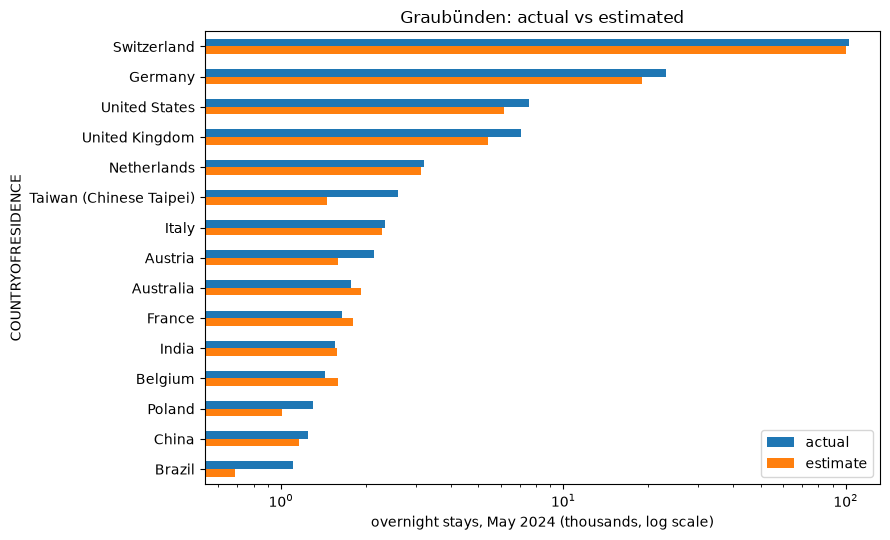

In [9]:
query, predicted = predictions_by_month[("2024-05", "sap-rpt-1.6-large, all rows, default")]
view = query.assign(estimate=np.expm1(predicted))
view = view[view["REGION"] == "Graubünden"].nlargest(15, "OVERNIGHTSTAYS")
axis = (view.set_index("COUNTRYOFRESIDENCE")[["OVERNIGHTSTAYS", "estimate"]]
        .rename(columns={"OVERNIGHTSTAYS": "actual"}) / 1e3).plot.barh(figsize=(9, 5.5))
axis.invert_yaxis()
axis.set_xscale("log")
axis.set_xlabel("overnight stays, May 2024 (thousands, log scale)")
axis.set_title("Graubünden: actual vs estimated")
plt.tight_layout()

## Takeaways

* **Prepare the table.** RPT reads each row on its own, so put the history into the row as columns, and predict numbers that range from very small to very large on a log scale. Both steps were needed for good accuracy on this data.
* **More context helped.** Going from 2,048 sampled rows on `sap-rpt-1.6` to all rows on `sap-rpt-1.6-large` reduced the error in every test month.
* **Follow SAP's sequence** (`sap-rpt-1.6`, then `sap-rpt-1.6-large` default, then `deep`) and measure each step on several test periods of your own data, including the latency.
* **Request mechanics:** up to 512 query rows per call, compressed bodies for large tables, and a longer client timeout for deep mode.